In [6]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)

In [7]:
setwd("/home/liuxuan/metadata/PRJNA362643")
initial_meta<-read.csv("SraRunTable.csv",header = T)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,Platform,ReleaseDate,Sample.Name,SRA.Study,X.SampleID,create_date,version,Forward_filename,Reverse_filename,title
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
1,SRR6445191,AMPLICON,456,2111038,PRJNA362643,SAMN08183545,Metagenome or environmental,1324319,STANFORD_ORAL_MICROBIOME,not applicable,⋯,LS454,2018-12-21T00:00:00Z,P2.1.09L.D01.R00,SRP126946,P2.1.09L.D01.R00,2018-01-05T15:45:00Z,1,,,
2,SRR6445192,AMPLICON,472,1984949,PRJNA362643,SAMN08183540,Metagenome or environmental,1203023,STANFORD_ORAL_MICROBIOME,not applicable,⋯,LS454,2018-12-21T00:00:00Z,P2.1.09B.D01.R01,SRP126946,P2.1.09B.D01.R01,2018-01-05T15:45:00Z,1,,,
3,SRR6445193,AMPLICON,467,2257387,PRJNA362643,SAMN08183539,Metagenome or environmental,1340767,STANFORD_ORAL_MICROBIOME,not applicable,⋯,LS454,2018-12-21T00:00:00Z,P2.1.09B.D01.R00,SRP126946,P2.1.09B.D01.R00,2018-01-05T15:45:00Z,1,,,
4,SRR6445194,AMPLICON,458,987268,PRJNA362643,SAMN08183538,Metagenome or environmental,652295,STANFORD_ORAL_MICROBIOME,not applicable,⋯,LS454,2018-12-21T00:00:00Z,P2.1.08L.D08.R01,SRP126946,P2.1.08L.D08.R01,2018-01-05T15:45:00Z,1,,,
5,SRR6445195,AMPLICON,465,1831897,PRJNA362643,SAMN08183537,Metagenome or environmental,1118657,STANFORD_ORAL_MICROBIOME,not applicable,⋯,LS454,2018-12-21T00:00:00Z,P2.1.08L.D08.R00,SRP126946,P2.1.08L.D08.R00,2018-01-05T15:45:00Z,1,,,
6,SRR6445196,AMPLICON,472,1620930,PRJNA362643,SAMN08183544,Metagenome or environmental,978619,STANFORD_ORAL_MICROBIOME,not applicable,⋯,LS454,2018-12-21T00:00:00Z,P2.1.09B.D08.R00,SRP126946,P2.1.09B.D08.R00,2018-01-05T15:45:00Z,1,,,


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "HOST"                           "Instrument"                    
[21] "isolation_source"               "lat_lon"                       
[23] "Library.Name"                   "LibraryLayout"                 
[25] "LibrarySelection"               "LibrarySource"                 
[27] "Organism"                       "Platform"                      
[29] "ReleaseDate"                    "Sample.Name"                   
[31] "SRA.Study"                      "X.SampleID"                    
[33] "create_date"                    "version"                       
[35] "Forward_filename"               "Reverse_filename"              
[37] "title"

In [8]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = "V4-V5",
    Platform = 'ILLUMINA',
    Country = NA,
    Site = initial_meta$isolation_source,
    public_time = initial_meta$create_date,
    PCR_primers = NA,
    title = 'A spatial gradient of bacterial diversity in the human oral cavity shaped by salivary flow',
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO'

)
print(length(unique(uniform_meta$Run)))

print(length(unique(uniform_meta$sample_name)))

[1] 9313
[1] 9313


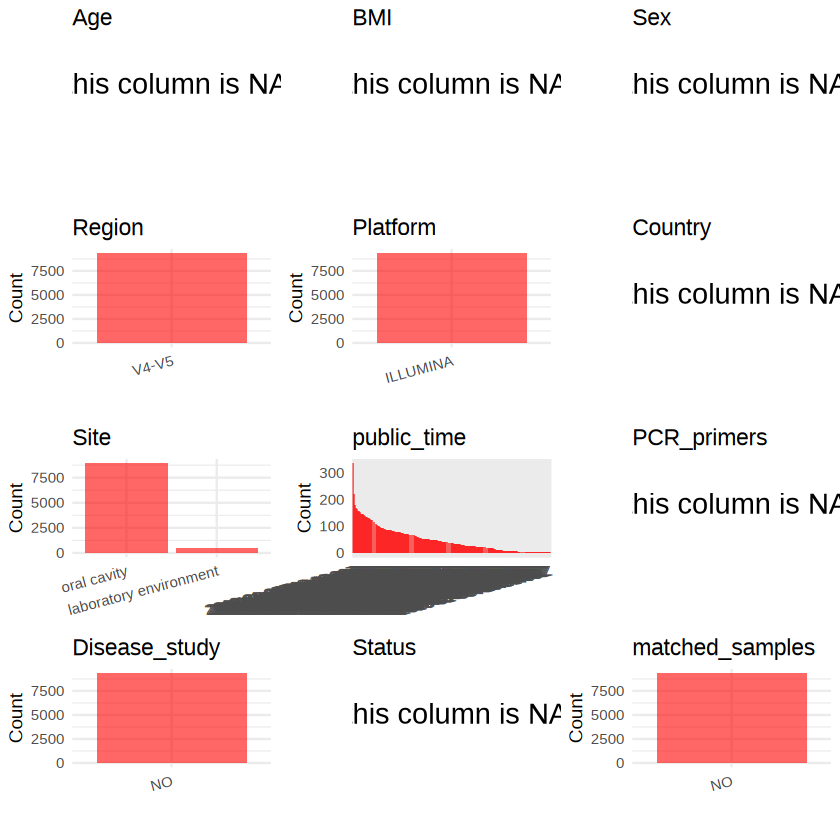

In [9]:
## plot the data
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)
create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    # Check if the column is all NA
    if (all(is.na(data[[col]]))) {
      # Create an empty plot with text indicating all NA
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      # Numeric variable: histogram
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      # Categorical variable: bar plot (remove NA values)
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  
  return(plots)
}
plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [10]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/PRJNA362643/metadata.csv", quote = F)